# Solar Power Generation Data Analysis
## Notebook 02 — Plant 2: The Case of the Missing Megawatts

**The story so far:** Plant 1 failed a basic physical check (DC power ≈ 10 × AC power), so we parked it and asked the operator.

Now we move to **Plant 2**. We run the same checks, then go deeper: how does the plant respond to sunlight and temperature? Along the way something will not add up, and we will investigate it like detectives: **formulate hypotheses, predict what each one would look like in the data, and test them.**

### Learning objectives
- Reuse the EDA workflow (completeness, plausibility) on a new dataset
- Combine generation and weather data and explore their relationships
- Test competing explanations against data instead of picking the first plausible story
- Recognise a classic trap: **correlation is not causation**

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

DATA = "../data"
generation_df = pd.read_csv(os.path.join(DATA, "Plant_2_Generation_Data.csv"))
weather_df = pd.read_csv(os.path.join(DATA, "Plant_2_Weather_Sensor_Data.csv"))

# Plant 2 uses the same timestamp format in both files
for df in (generation_df, weather_df):
    df['DATE_TIME'] = pd.to_datetime(df['DATE_TIME'], format='%Y-%m-%d %H:%M:%S')
    df['DAY'] = df['DATE_TIME'].dt.date
    df['HOUR'] = df['DATE_TIME'].dt.hour

print(f"Generation data: {generation_df.shape} — {generation_df['SOURCE_KEY'].nunique()} inverters")
print(f"Weather data:    {weather_df.shape}")

Generation data: (67698, 9) — 22 inverters
Weather data:    (3259, 8)


## Act 2

### 2.1 Completeness
Same check as Plant 1: records received per inverter per day, out of 96.

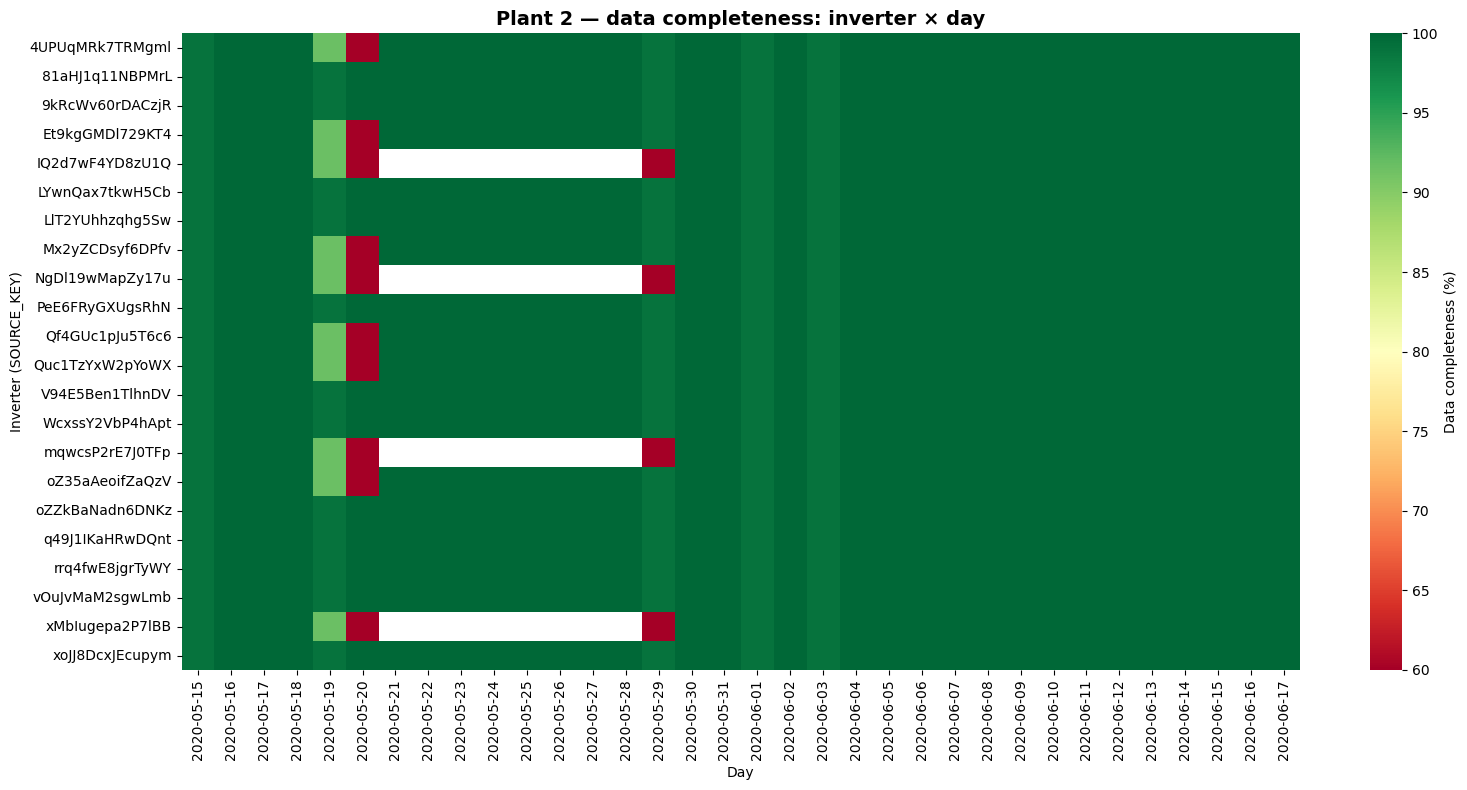

In [2]:
SAMPLES_PER_DAY = 96

completeness = (
    generation_df.groupby(['SOURCE_KEY', 'DAY']).size()
    .div(SAMPLES_PER_DAY).mul(100)
    .unstack()
)

plt.figure(figsize=(16, 8))
sns.heatmap(completeness, cmap='RdYlGn', vmin=60, vmax=100,
            cbar_kws={'label': 'Data completeness (%)'})
plt.grid(False)
plt.title('Plant 2 — data completeness: inverter × day', fontsize=14, fontweight='bold')
plt.xlabel('Day')
plt.ylabel('Inverter (SOURCE_KEY)')
plt.tight_layout()
plt.show()

> Plant 2 shows **two clusters** of inverters: one with near-complete data, one with a block of missing days (white) at the end of May.
>
> To keep the analysis clean we keep only inverters with **more than 98% average completeness**. The other cluster is a good exercise to explore on your own.

In [3]:
THRESHOLD = 98.0
avg_completeness = completeness.mean(axis=1)
high_quality = avg_completeness[avg_completeness > THRESHOLD].index.tolist()

generation_df = generation_df[generation_df['SOURCE_KEY'].isin(high_quality)].copy()
print(f"High-quality inverters: {len(high_quality)} of {len(avg_completeness)}")

High-quality inverters: 12 of 22


### 2.2 Plausibility: the Plant 1 check
Does Plant 2 pass the DC → AC conversion test that Plant 1 failed?

In [4]:
producing = generation_df[generation_df['DC_POWER'] > 0]
efficiency = producing['AC_POWER'] / producing['DC_POWER'] * 100

print(f"DC → AC conversion efficiency — median: {efficiency.median():.1f}%")
print(f"5th–95th percentile: {efficiency.quantile(0.05):.1f}% – {efficiency.quantile(0.95):.1f}%")

DC → AC conversion efficiency — median: 97.8%
5th–95th percentile: 96.6% – 98.2%


> ✅ ~97.8%: within the typical range of a modern inverter. Units look consistent this time.

### 2.3 Distribution of DC power
Most readings at night are zero, so we look at **productive readings** only.

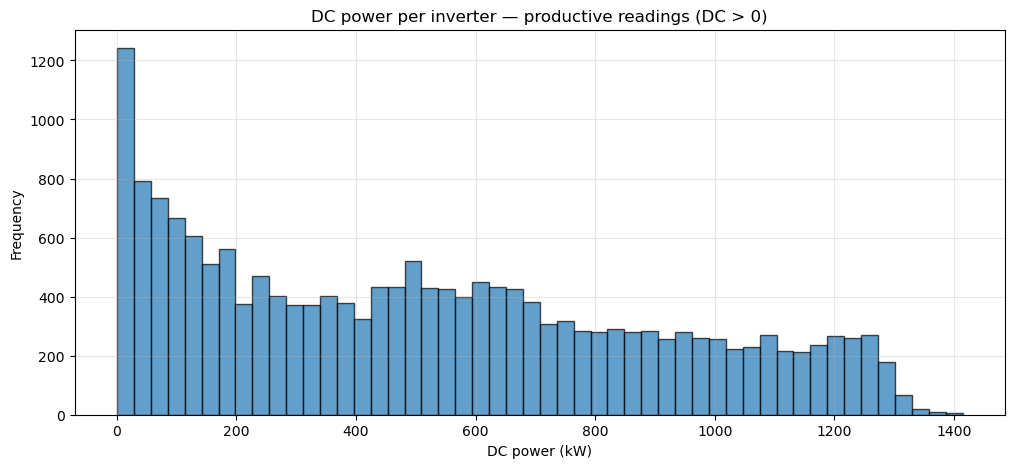

In [5]:
plt.hist(generation_df.loc[generation_df['DC_POWER'] > 0, 'DC_POWER'], bins=50, edgecolor='black', alpha=0.7)
plt.title('DC power per inverter — productive readings (DC > 0)')
plt.xlabel('DC power (kW)')
plt.ylabel('Frequency')
plt.show()

> Right-skewed: many readings at low power (morning, evening), fewer at peak. Nothing alarming.
>
> **Plant 2 passes completeness and plausibility. Time to look at how the plant responds to the weather.**

## Act 3

### 3.1 Combine generation and weather
Weather is measured at plant level, generation at inverter level. We **sum** the power of all inverters at each timestamp, then **merge** with the weather data.

In [6]:
plant_df = generation_df.groupby('DATE_TIME')[['DC_POWER', 'AC_POWER']].sum().reset_index()
print(f"Shape before merge: {plant_df.shape}")

merged = plant_df.merge(
    weather_df[['DATE_TIME', 'IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'HOUR']],
    on='DATE_TIME', how='inner')
print(f"Shape after merge:  {merged.shape}")
print(f"Missing values after merge: {merged.isnull().sum().sum()}")

Shape before merge: (3259, 3)
Shape after merge:  (3259, 7)
Missing values after merge: 0


> **Best practice:** always check the shape and the nulls after a merge. Merges can silently drop or duplicate rows.

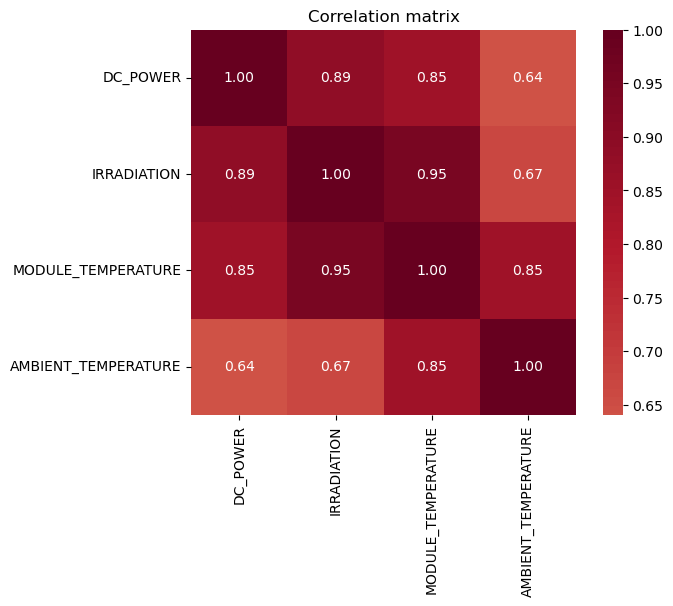

In [7]:
cols = ['DC_POWER', 'IRRADIATION', 'MODULE_TEMPERATURE', 'AMBIENT_TEMPERATURE']
plt.figure(figsize=(7, 5))
sns.heatmap(merged[cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, square=True)
plt.grid(False)
plt.title('Correlation matrix')
plt.show()

> Irradiation and DC power are strongly correlated (≈ 0.9): more sun, more power.
>

### 3.2 Irradiation vs DC power
Physics gives a simple expectation: **DC power grows in proportion to the sunlight.** Double the sun, double the power.

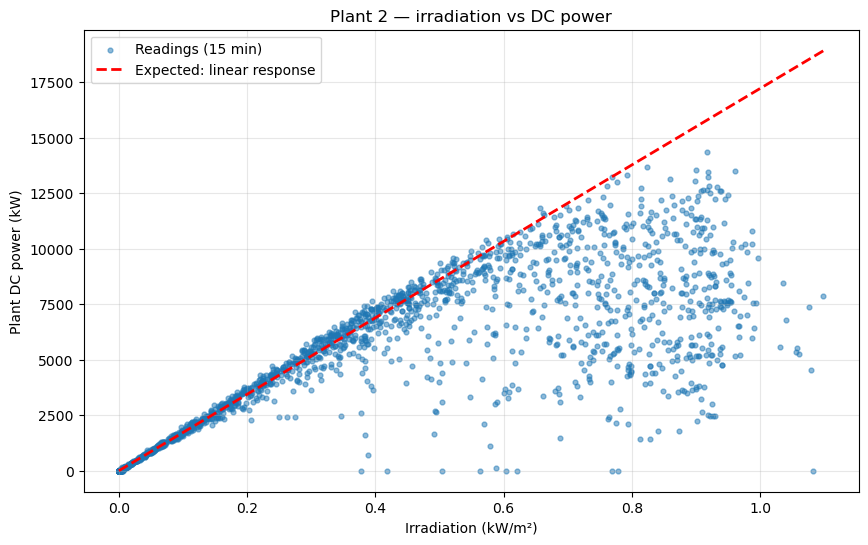

k ≈ 17,209 m²  → expected DC power at 1 kW/m²: 17.2 MW
Sanity check — sum of each inverter's maximum DC power: 16.5 MW


In [9]:
# Expected behaviour: DC ≈ k × IRRADIATION
low = merged[(merged['IRRADIATION'] > 0.05) & (merged['IRRADIATION'] < 0.3)]
k = (low['DC_POWER'] * low['IRRADIATION']).sum() / (low['IRRADIATION'] ** 2).sum()

x = np.linspace(0, merged['IRRADIATION'].max(), 50)
plt.figure(figsize=(10, 6))
plt.scatter(merged['IRRADIATION'], merged['DC_POWER'], s=12, alpha=0.5, label='Readings (15 min)')
plt.plot(x, k * x, 'r--', linewidth=2, label='Expected: linear response')
plt.xlabel('Irradiation (kW/m²)')
plt.ylabel('Plant DC power (kW)')
plt.title('Plant 2 — irradiation vs DC power')
plt.legend()
plt.show()

dc_capacity_proxy = generation_df.groupby('SOURCE_KEY')['DC_POWER'].max().sum()
print(f"k ≈ {k:,.0f} m²  → expected DC power at 1 kW/m²: {k / 1000:,.1f} MW")
print(f"Sanity check — sum of each inverter's maximum DC power: {dc_capacity_proxy / 1000:,.1f} MW")

> The line is physically sensible: at 1 kW/m² it predicts 17.2 MW, close to the 16.5 MW the inverters actually reach at their best.
>
> **Something doesn't add up.** Up to ~0.4 kW/m² the plant follows the line closely. Above that, many readings fall **far below** the expected output, some close to zero, while the sun is at its strongest.
>
> On the sunniest moments we are missing a large share of the power. **Where are the missing megawatts?**

#### What is k?
k answers one question: **how many kW does the plant give us for each unit of sunlight?**

Three real readings from Plant 2, early morning and late afternoon:

| When | Sunlight G (kW/m²) | Plant power P (kW) | P ÷ G |
|---|---|---|---|
| 29 May, 07:00 | 0.10 | 1,573 | ~15,800 |
| 16 Jun, 07:45 | 0.20 | 3,519 | ~17,600 |
| 15 May, 16:45 | 0.30 | 5,242 | ~17,500 |

The ratio P ÷ G is almost constant, around 17,500. That constant is **k**, and the expected behaviour is a straight line:

$$P = k \times G$$

**How we compute it.** With hundreds of readings, each slightly noisy, we need one value that fits them all. `k = Σ(P·G) / Σ(G²)` is the slope of the line through the origin that best fits all the points (least squares). Think of it as a well-made average of P ÷ G that gives more weight to the sunnier, more reliable readings.

**Units: why k is an area.** k = kW ÷ (kW/m²) = **m²**. Think of rain: rainfall is measured *per m²*, and the litres a roof collects = rain per m² × roof area. Sunlight also arrives *per m²*; the plant turns it into *total* kW. The "area" that does the conversion is k. It is an **effective area**: real panel area × panel efficiency (panels convert only ~15–20% of the sunlight they receive).

**Why it is useful.** Panels are rated at a standard sunlight of **1 kW/m²**. At G = 1, P = k: so k, read in kW, is roughly the **DC size of the plant**. A built-in sanity check.

**Why only low-sunlight readings (0.05–0.3 kW/m²).** In those hours the plant behaves by the book: panels are cool, inverters are far from their limit, and (we will discover) problems happen at midday. We measure how the plant behaves **when it is healthy**, then use it as the expectation for the rest of the day.

## Act 4 

| Suspect | The story |
|---|---|
|  **Heat** | Hot panels are less efficient |
|  **Clipping** | The inverter caps its output at its rated power |
|  **Outages** | Some inverters stop producing |

For each suspect we ask: **if this were the cause, what would we see in the data?** Then we check.

### Suspect 1 — Heat 
Colour the scatter by module temperature.

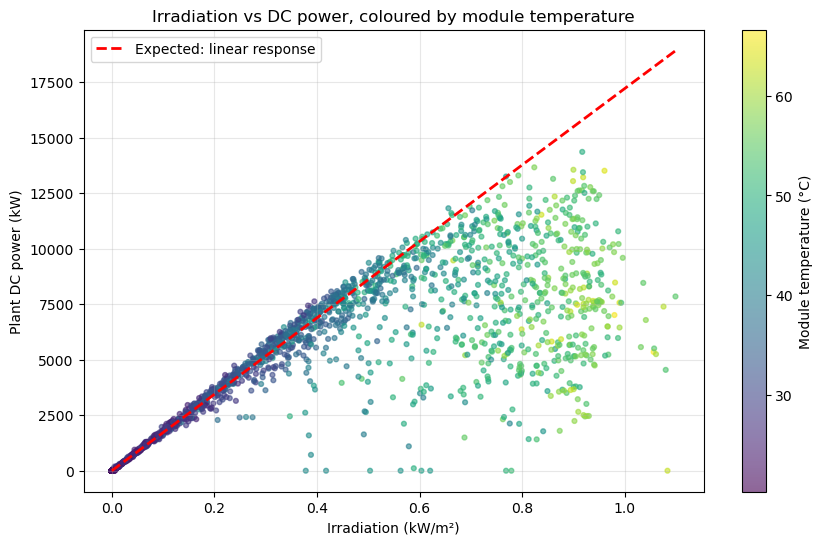

In [10]:
plt.figure(figsize=(10, 6))
sc = plt.scatter(merged['IRRADIATION'], merged['DC_POWER'], c=merged['MODULE_TEMPERATURE'],
                 cmap='viridis', s=12, alpha=0.6)
plt.plot(x, k * x, 'r--', linewidth=2, label='Expected: linear response')
plt.colorbar(sc, label='Module temperature (°C)')
plt.xlabel('Irradiation (kW/m²)')
plt.ylabel('Plant DC power (kW)')
plt.title('Irradiation vs DC power, coloured by module temperature')
plt.legend()
plt.show()

> The low readings are the **hot** ones. Case closed? Not yet.
>
> **What heat would look like:** every module datasheet reports a *temperature coefficient of power*, measured under IEC 61215 / IEC 60891. For crystalline silicon it is typically between **−0.35% and −0.47% per °C** above 25 °C (NREL PVWatts uses −0.47% for "standard" and −0.35% for "premium" modules). We use **−0.4%/°C**: going from 25 °C to 60 °C should cost roughly **14%**. Let's compare that with what we observe at high irradiation.

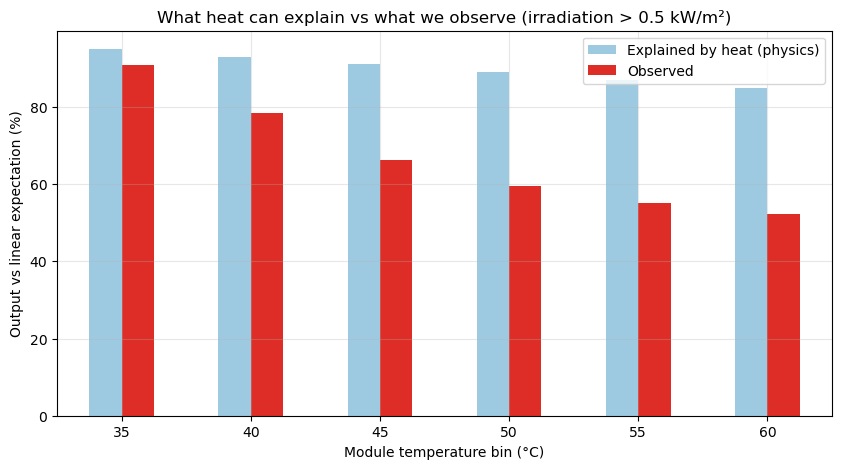

,observed,readings,heat_only
temp_bin,,,
35,0.91,42,0.95
40,0.79,93,0.93
45,0.66,170,0.91
50,0.59,218,0.89
55,0.55,160,0.87
60,0.52,30,0.85


In [11]:
GAMMA = -0.004   # typical temperature coefficient of crystalline silicon (per °C)

sunny = merged[merged['IRRADIATION'] > 0.5].copy()
sunny['observed_vs_expected'] = sunny['DC_POWER'] / (k * sunny['IRRADIATION'])
sunny['temp_bin'] = (sunny['MODULE_TEMPERATURE'] // 5 * 5).astype(int)

check = sunny.groupby('temp_bin').agg(observed=('observed_vs_expected', 'mean'),
                                      readings=('observed_vs_expected', 'size'))
check = check[check['readings'] >= 20]
check['heat_only'] = 1 + GAMMA * (check.index + 2.5 - 25)

ax = check[['heat_only', 'observed']].mul(100).plot(kind='bar', figsize=(10, 5), color=['#9ecae1', '#de2d26'])
ax.set_xlabel('Module temperature bin (°C)')
ax.set_ylabel('Output vs linear expectation (%)')
ax.set_title('What heat can explain vs what we observe (irradiation > 0.5 kW/m²)')
ax.legend(['Explained by heat (physics)', 'Observed'])
plt.xticks(rotation=0)
plt.show()

check.round(2)

> At 50–60 °C heat explains a loss of 10–15% (17% even with the most pessimistic −0.47%/°C). We observe a loss of **40–50%**.
>
> **Verdict: heat is a minor accomplice, not the culprit.** Then why the strong correlation? Because module temperature and the missing power share the same driver: **midday**. Hot modules and the real cause happen at the same time, so they correlate without one causing the other. Correlation is not causation.

<details>
<summary><b>Side note — module vs air temperature (optional)</b></summary>

Plotting module temperature against ambient temperature, coloured by hour, gives a loop. Modules heat up as soon as the sun rises, while the air warms up slowly and peaks in the afternoon. The module follows the **sun**, the air **lags behind** it. In the evening the two converge quickly.
</details>

### Suspect 2 — Clipping

> **📖 Clipping.** An inverter has a maximum AC output, its *rated power*. Plants are deliberately built with more panel capacity than inverter capacity (DC/AC ratio, typically 1.1–1.3), because panels reach full power only a few hours a year. When the panels could deliver more than the rating, the inverter **limits its output to the rating** and the surplus is lost. In formula (NREL PVWatts inverter model):
>
> $$P_{AC} = \min(\eta \cdot P_{DC},\ P_{AC,rated})$$
>
> To do this, the inverter moves the panels away from their maximum power point, so **DC power flattens too**. Clipping is a design choice: a small, planned loss in exchange for a cheaper inverter and more energy in the morning and afternoon.

Average actual vs expected DC power by time of day.

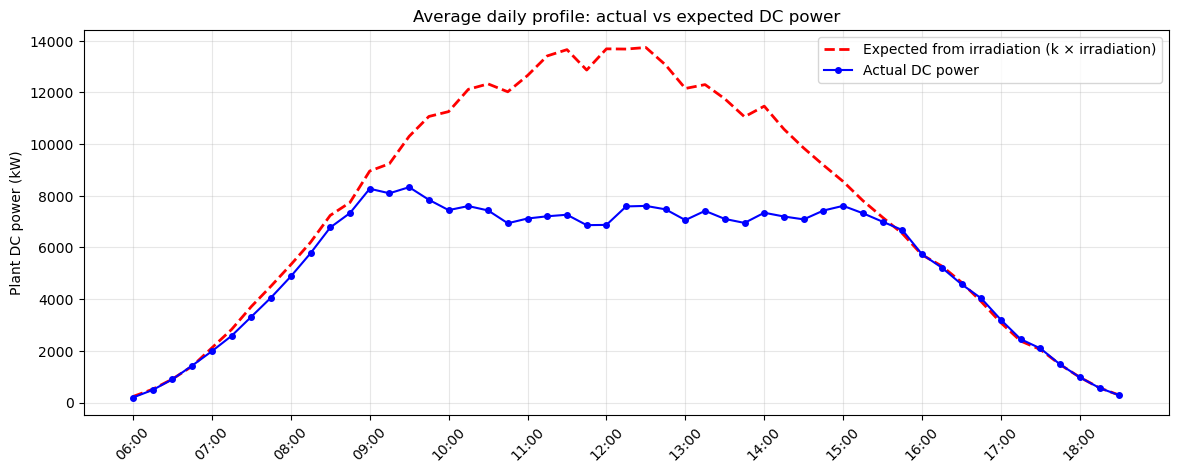

In [13]:
daylight = merged[merged['IRRADIATION'] > 0.01].copy()
daylight['TIME'] = daylight['DATE_TIME'].dt.strftime('%H:%M')
profile = daylight.groupby('TIME')[['IRRADIATION', 'DC_POWER']].mean()
profile['EXPECTED_DC'] = k * profile['IRRADIATION']

plt.figure(figsize=(14, 5))
plt.plot(profile.index, profile['EXPECTED_DC'], 'r--', linewidth=2, label='Expected from irradiation (k × irradiation)')
plt.plot(profile.index, profile['DC_POWER'], color='blue', marker='o', markersize=4, label='Actual DC power')
plt.xticks(range(0, len(profile), 4), profile.index[::4], rotation=45)
plt.ylabel('Plant DC power (kW)')
plt.title('Average daily profile: actual vs expected DC power')
plt.legend()
plt.show()

> Actual DC power **flattens** from 9:00 to 15:00 at about half of what the sun would allow, while the expected curve keeps rising to its noon peak. It really looks like clipping.
>
> **What clipping would look like:** an inverter that caps its output produces readings that **pile up at a ceiling** (its rated power). Let's look at individual inverter readings when the sun is strong.

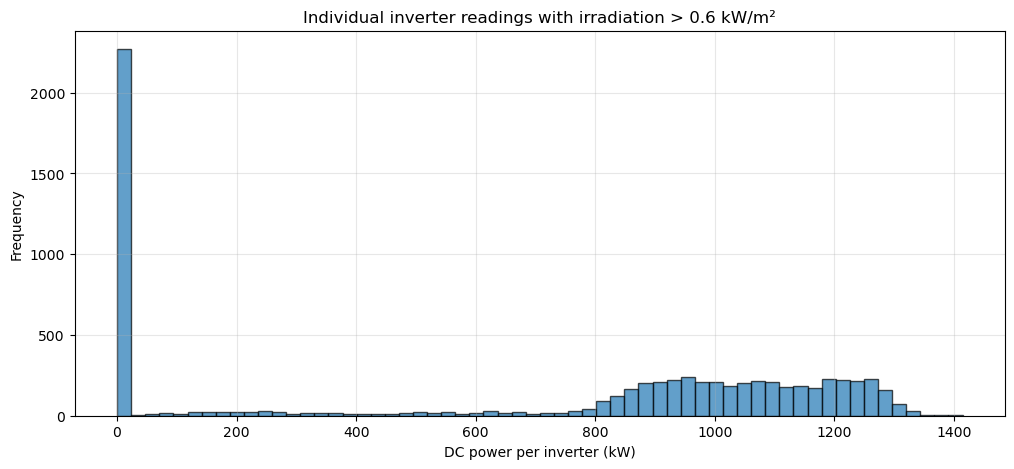

Readings at zero under strong sun: 32%


In [14]:
inv = generation_df.merge(weather_df[['DATE_TIME', 'IRRADIATION']], on='DATE_TIME')
strong_sun = inv[inv['IRRADIATION'] > 0.6]

plt.hist(strong_sun['DC_POWER'], bins=60, edgecolor='black', alpha=0.7)
plt.xlabel('DC power per inverter (kW)')
plt.ylabel('Frequency')
plt.title('Individual inverter readings with irradiation > 0.6 kW/m²')
plt.show()

share_zero = (strong_sun['DC_POWER'] < 1).mean() * 100
print(f"Readings at zero under strong sun: {share_zero:.0f}%")

> Readings thin out around 1,300 kW (the inverter's size), but they do not stack up against it: no ceiling effect. At most, a little clipping on the brightest moments. Instead, a huge spike **at zero**: about **one reading in three** under full sun.
>
> And remember the histogram in Act 2? We filtered `DC_POWER > 0` and **hid exactly these readings**. A filter that looks harmless can remove the evidence.

**Verdict: no sign of clipping.** But we have a new lead.

### Suspect 3 — Outages

> **📖 Outage.** A period in which equipment that should be producing is **not available**: output drops to zero although the resource (sunlight) is there. Outages are *planned* (maintenance) or *forced* (failures). The usual causes in a PV plant:
> - **Inverter trip**: the inverter disconnects itself to protect itself or the grid (voltage or frequency out of limits, overheating, insulation fault), then tries to reconnect after a delay.
> - **Curtailment**: the grid operator (or the plant's own controller) orders the plant to reduce or stop production, e.g. for grid congestion or excess supply.
> - **Communication / logging failure**: the inverter produces, but the monitoring system records zero.
>
> The share of time (or energy) in which the plant is available is its **availability**, a key KPI in O&M contracts (framework: IEC TS 63019).

**What outages would look like:** individual inverters dropping to zero while the sun is shining and the other inverters keep producing.

Let's count zero readings under the sun (irradiation > 0.1 kW/m²), by hour and by inverter-day.

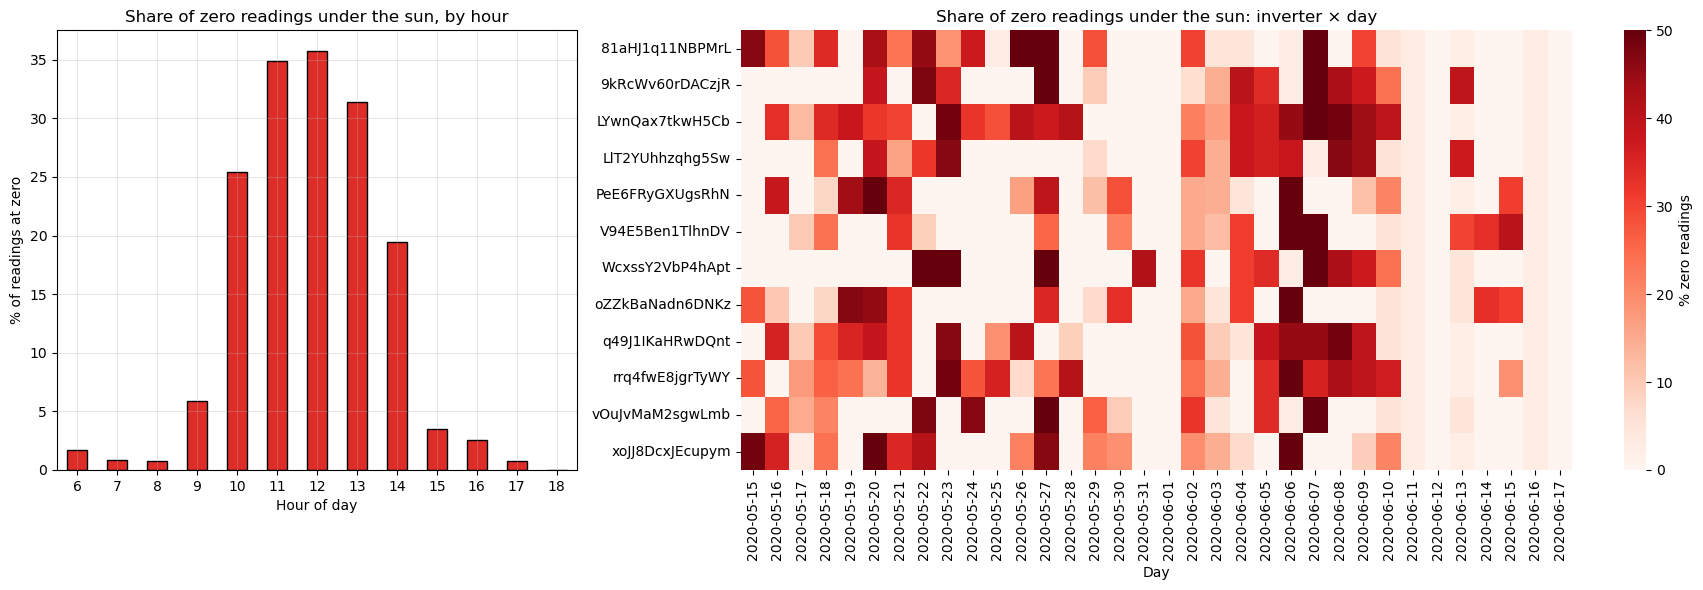

Zero readings under the sun: 16% overall


In [15]:
sun = inv[inv['IRRADIATION'] > 0.1].copy()
sun['is_zero'] = sun['DC_POWER'] < 1

fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={'width_ratios': [1, 2]})

sun.groupby('HOUR')['is_zero'].mean().mul(100).plot(kind='bar', ax=axes[0], color='#de2d26', edgecolor='black')
axes[0].set_title('Share of zero readings under the sun, by hour')
axes[0].set_xlabel('Hour of day')
axes[0].set_ylabel('% of readings at zero')
axes[0].tick_params(axis='x', rotation=0)

zero_map = sun.groupby(['SOURCE_KEY', 'DAY'])['is_zero'].mean().mul(100).unstack()
sns.heatmap(zero_map, cmap='Reds', vmin=0, vmax=50, ax=axes[1], cbar_kws={'label': '% zero readings'})
axes[1].grid(False)
axes[1].set_title('Share of zero readings under the sun: inverter × day')
axes[1].set_xlabel('Day')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

print(f"Zero readings under the sun: {sun['is_zero'].mean() * 100:.0f}% overall")

>  **Found them.** About **one reading in six** under the sun is zero, up to **one in three around noon**. The zeros concentrate between **10:00 and 14:00** and hit **all inverters**, on most days until early June. The last week is almost clean.
>
> Are they plant-wide events (all inverters at once) or individual inverters? And what does a single episode look like?

Inverters at zero at the same moment (out of 12):
1     101
2      72
3      77
4      70
5      53
6      79
7      54
8      53
9      15
10      5
12      9


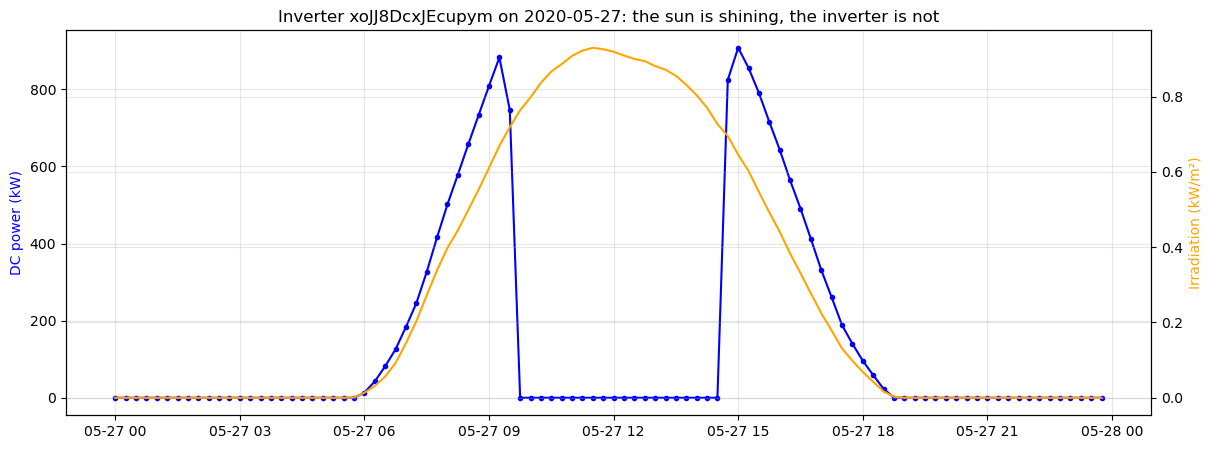

In [16]:
zeros_per_timestamp = sun[sun['is_zero']].groupby('DATE_TIME').size()
print("Inverters at zero at the same moment (out of 12):")
print(zeros_per_timestamp.value_counts().sort_index().to_string())

# One episode up close
inverter, day = 'xoJJ8DcxJEcupym', pd.to_datetime('2020-05-27').date()
one = inv[(inv['SOURCE_KEY'] == inverter) & (inv['DATE_TIME'].dt.date == day)].sort_values('DATE_TIME')

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(one['DATE_TIME'], one['DC_POWER'], color='blue', marker='o', markersize=3, label='DC power')
ax1.set_ylabel('DC power (kW)', color='blue')
ax2 = ax1.twinx()
ax2.plot(one['DATE_TIME'], one['IRRADIATION'], color='orange', label='Irradiation')
ax2.set_ylabel('Irradiation (kW/m²)', color='orange')
ax1.set_title(f'Inverter {inverter} on {day}: the sun is shining, the inverter is not')
plt.show()

> Most episodes involve **a few inverters at a time**, rarely the whole plant. In the example, the inverter stops just before 10:00 and restarts at 14:45, under full sun, while its neighbours keep producing.
>
> **Verdict: outages are the main culprit.**

### Final check: put the pieces back together
If outages are the culprit, two things must be true:
1. the "missing" readings in the scatter from Act 3 are the moments with inverters at zero;
2. when **all 12 inverters are running**, the plant should behave as physics predicts, with only the heat loss left.

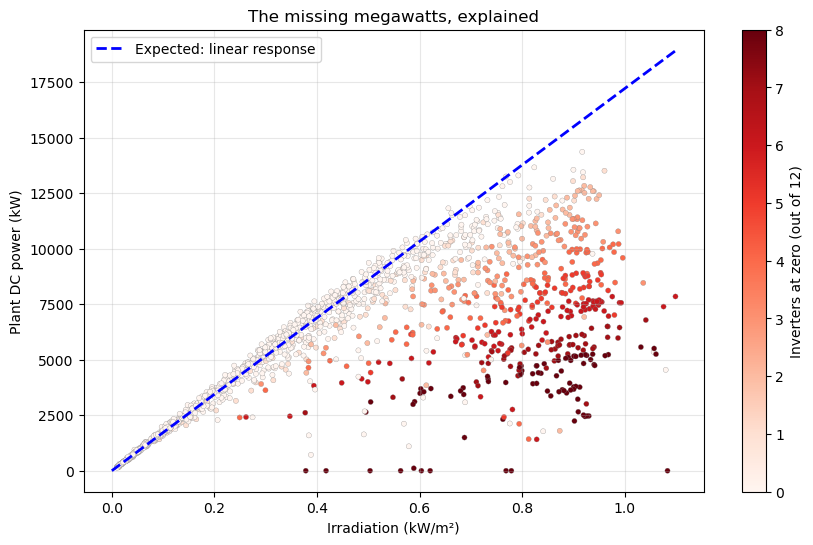

All inverters running, irradiation > 0.5 — observed vs expected: 89%
What heat alone would predict at the same temperatures:          92%


In [17]:
zeros_now = (inv.assign(is_zero=inv['DC_POWER'] < 1)
             .groupby('DATE_TIME')['is_zero'].sum().rename('INVERTERS_AT_ZERO'))
check_df = merged.merge(zeros_now, on='DATE_TIME')
check_df = check_df[check_df['IRRADIATION'] > 0.01]

plt.figure(figsize=(10, 6))
sc = plt.scatter(check_df['IRRADIATION'], check_df['DC_POWER'], c=check_df['INVERTERS_AT_ZERO'],
                 cmap='Reds', vmin=0, vmax=8, s=14, edgecolors='grey', linewidths=0.2)
plt.plot(x, k * x, 'b--', linewidth=2, label='Expected: linear response')
plt.colorbar(sc, label='Inverters at zero (out of 12)')
plt.xlabel('Irradiation (kW/m²)')
plt.ylabel('Plant DC power (kW)')
plt.title('The missing megawatts, explained')
plt.legend()
plt.show()

all_on = check_df[(check_df['IRRADIATION'] > 0.5) & (check_df['INVERTERS_AT_ZERO'] == 0)]
observed = (all_on['DC_POWER'] / (k * all_on['IRRADIATION'])).mean()
heat_only = (1 + GAMMA * (all_on['MODULE_TEMPERATURE'] - 25)).mean()
print(f"All inverters running, irradiation > 0.5 — observed vs expected: {observed:.0%}")
print(f"What heat alone would predict at the same temperatures:          {heat_only:.0%}")

> The hole in the scatter is made of **red** points: moments with inverters down. When all inverters are running, the plant delivers 89% of the linear expectation, within a few points of the 92% that heat alone would predict. **The missing megawatts are accounted for.**

## How big is the problem?
For every zero reading under the sun we estimate what the inverter **would have produced**: the median AC power of the inverters that were running at the same moment. Power × 0.25 h = energy (see Notebook 01).

In [20]:
# Use active inverters to estimate the plant's typical AC output at each timestamp.
running = inv[inv['DC_POWER'] >= 1]
peer_median = running.groupby('DATE_TIME')['AC_POWER'].median()

# For timestamps when this inverter was producing no power, estimate its
# expected output using the median output of the other active inverters.
lost = sun[sun['is_zero']].copy()
lost['EXPECTED_AC'] = lost['DATE_TIME'].map(peer_median).fillna(0)

# Convert 15-minute power readings from watts to MWh, then calculate totals.
lost_mwh = (lost['EXPECTED_AC'] * 0.25).sum() / 1000
produced_mwh = (generation_df['AC_POWER'] * 0.25).sum() / 1000
days = generation_df['DAY'].nunique()

# Summarize actual generation, estimated outage losses, and their share
# of the combined potential generation.
print(f"Energy produced:        {produced_mwh:,.0f} MWh in {days} days")
print(f"Energy lost to outages: {lost_mwh:,.0f} MWh")
print(f"Share of potential:     {lost_mwh / (lost_mwh + produced_mwh):.0%}")

# Express the estimated lost energy as an equivalent number of average
# production days over the observed period.
print(f"Equivalent to:          {lost_mwh / (produced_mwh / days):.0f} days of production lost out of {days}")

Energy produced:        2,285 MWh in 34 days
Energy lost to outages: 641 MWh
Share of potential:     22%
Equivalent to:          10 days of production lost out of 34


## Case closed 

| Suspect | What we would expect | What we observed | Verdict |
|---|---|---|---|
|  Heat | −0.35 to −0.47%/°C: 10–17% loss at 50–60 °C | 40–50% loss overall; only 11% when all inverters run | Explains the normal loss, not the missing megawatts |
|  Clipping | Readings piling up at the inverter's rating | No ceiling; a spike at **zero** | Not the explanation |
|  Outages | Inverters at zero under the sun while peers produce | 16% of sunny readings at zero, ~35% at noon | **Guilty** |

**Plant 2 does not have a physics problem. It has an availability problem.** Roughly one megawatt-hour in five that the sun delivered never reached the grid, and the losses are concentrated in the most productive hours of the day.

### So what? From finding to action

| What we found | Why it matters for the business | Action |
|---|---|---|
| ~1/5 of potential energy lost to outages | Lost energy is lost revenue: the equivalent of **10 days of production out of 34** | Quantify in € and check the **availability guarantee** in the O&M contract |
| Outages hit few inverters at a time, around noon | Points to a **recurring technical cause**, not bad luck | Send the operator the list of timestamps; compare with alarm logs |
| A simple rule finds them: *inverter at zero, sun shining, peers producing* | Detection needs **no machine learning**: a rule can run on live data tomorrow | Turn the rule into a daily **alert** for O&M |

### Questions for the plant operator
Data tells us **what** happens and **when**. It cannot tell us **why**.
- **Inverter trips, curtailment or logging?** The alarm logs and the grid operator's dispatch orders can tell them apart.
- **Why midday?** When the plant injects the most power, the voltage at its connection point rises. Overvoltage trips are a classic suspect worth checking.
- **Why almost none in the last week?** Was something fixed in early June?

### Three lessons to take home
1. **Complete ≠ correct.** 98% completeness hid one sunny reading in six at zero, and a harmless-looking filter (`DC_POWER > 0`) hid them again.
2. **A plausible story is a hypothesis, not a finding.** Heat and clipping both *looked* right. Writing down what each would look like in the data is what killed them.
3. **Domain knowledge beats algorithms.** The diagnosis came from a scatter plot, two physics facts and a few lines of pandas. No model needed.

➡️ **Next:** any model trained on this data will learn that the plant "underperforms at noon". What does that do to a forecast, and what is a forecast error worth?